In [95]:
using BifurcationKit, LinearAlgebra,CairoMakie
const BK = BifurcationKit

function var_transform(ϕp,X,ψ,p)
    (;λ)=p
    ucharge,usalt,ucat,uκ=X
    ϕcharge=(1-ϕp)/(1+exp(ucharge))
    ϕOH=ϕcharge/(1+exp(usalt))
    ϕsalt=ϕcharge*exp(usalt)/(1+exp(usalt))
    ϕcat=ϕsalt*exp(ucat)/(1+exp(ucat))
    ϕan=ϕsalt*1/(1+exp(ucat))
    κ=sqrt(λ)/(1+exp(uκ))
    μDH=-λ/(8*π)*κ/(1+κ)

    return (ϕp,ϕcat,ϕan,ϕOH,ψ,κ,μDH)
end
# Define the free energy
function f(ϕ,p)
    (; χ, λ, Npoly,zp,zcat,zan) = p
    ϕp,ϕcat,ϕan,ϕOH,ψ,κ,μDH=ϕ
    
    
    ϕs=1-ϕp-ϕcat-ϕan-ϕOH
    fmix=ϕp*log(ϕp)/Npoly+ϕs*log(ϕs)+ϕcat*log(ϕcat)+ϕan*log(ϕan)+ϕOH*log(ϕOH)
    fFH = χ * ϕp *ϕs
    fDH = μDH*(-κ^2/λ+zcat^2*ϕcat+zan^2*ϕan+zp*ϕp+ϕOH)-(1/(4π)) * (log(1 +κ) - κ+ κ^2/2)+ψ*(zcat*ϕcat-zan*ϕan-ϕOH+zp*ϕp)

    return fmix+fFH+fDH
end
function electroneutrality(ϕ,p)
    (; χ, λ, Npoly,zp,zcat,zan) = p
    ϕp,ϕcat,ϕan,ϕOH,ψ,κ,_=ϕ

    
    return [zcat*ϕcat-zan*ϕan-ϕOH+zp*ϕp,-κ^2/λ+zcat^2*ϕcat+zan^2*ϕan+zp*ϕp+ϕOH]
end
function total_salt(ϕp1,X,p)
    (;Np) = p
    ϕvar1=var_transform(ϕp1,X[1:4],0,p)
    uphiP2= X[5]
    ϕp2 = exp(uphiP2)/(1+exp(uphiP2))
    ϕvar2=var_transform(ϕp2,X[6:9],X[10],p)
    
    ν=(Np-ϕp2)/(ϕp1-ϕp2)

    return ν*ϕvar1[2]+(1-ν)*ϕvar2[2]
end

function μ_values(ϕ, p)
    (; χ, Npoly,λ,zp,zcat,zan) = p
    ϕp,ϕcat,ϕan,ϕOH,ψ,κ,μDH=ϕ

    ϕs=1-ϕp-ϕcat-ϕan-ϕOH
    μ_p = log(ϕp)/Npoly-log(ϕs)+χ*(ϕs-ϕp)+1/Npoly-1+zp*(ψ+μDH)
    μ_cat = log(ϕcat/ϕs)-χ*ϕp+zcat*(ψ+zcat*μDH)
    μ_an=log(ϕan/ϕs)-χ*ϕp+zan*(-ψ+zan*μDH)
    μ_OH = log(ϕOH/ϕs)-χ*ϕp-ψ+μDH

    return [μ_p,μ_cat,μ_an,μ_OH]
end

# Coexistnece equations to solve
function coexistence_system(X, p)
    (;exphiP1,Np,zcat,zan)=p
    F=similar(X)
    uphiP2= X[5]
    ϕp1 = 10^exphiP1
    ϕp2 = exp(uphiP2)/(1+exp(uphiP2))
    
    ϕvar1=var_transform(ϕp1,X[1:4],0,p)
  
    ϕvar2=var_transform(ϕp2,X[6:9],X[10],p)

    f1 = f(ϕvar1,p)
    f2 = f(ϕvar2,p)

    μ1 = μ_values(ϕvar1,p)
    μ2 = μ_values(ϕvar2,p)


    dϕp=ϕp1 - ϕp2
    dϕcat=ϕvar1[2]-ϕvar2[2]
    dϕan=ϕvar1[3]-ϕvar2[3]
    dϕOH=ϕvar1[4]-ϕvar2[4]

    F[1]=μ1[1]-μ2[1]
    F[2]=μ1[2]-μ2[2]
    F[3:4]=electroneutrality(ϕvar1,p) #defines electric field jump and κ
    F[5] = ((f1 - f2) - μ1[1]*dϕp - dϕcat*μ1[2]-dϕan*μ1[3]-dϕOH*μ1[4]) #defined \phip2
    F[6]=μ1[3]-μ2[3] # defines OH
    F[7]=μ1[4]-μ2[4] # defines cat 2
    F[8]= (Np-ϕvar1[1])*(ϕvar2[2]*zan-ϕvar2[3]*zcat)/dϕp+(ϕvar2[1]-Np)*(ϕvar1[2]*zan-ϕvar1[3]*zcat)/dϕp# overall condition
    F[9:10]=electroneutrality(ϕvar2,p)
    return F
end

Nmonomer=50.
meanϕP=1.5*1e-3*Nmonomer/55.35
# System parameters
p = (exphiP1 = log10(meanϕP),#log10(1e-3), # Initial guess
    χ =0.855,
    Np=1.5*1e-3*Nmonomer/55.35,
    λ = 120.,#26.68,
    Npoly = Nmonomer,
    zp=2/Nmonomer,zcat=1.,zan=1)

# Initial guess
X0 = [1.6337310789746535, 8.009342931872826, 0.00017419649593560703, 0.3889257048797199, -0.0924546446784392, 1.1861505360989448, 7.864675170336844, -0.31365621047513365, 0.506120820907485, 0.1569152034855347]
X0top=[3.4679437338764183, 6.321018660689539, 4.077671459348683e-17, 1.558030529853911, -0.11503461231533173, 2.6044674821520104, 5.904602988221793, -1.14315296016782, 1.1799407656513001, 0.5715764800839099]
X0down=[8.996302101481373, 0.24839555644576086, -8.011710857504563e-17, 4.303761296134204, -0.011274332134985887, 3.1879610565713645, -0.4424993319458687, -6.094680482406037, 1.3892759157266497, 3.047340241203018]

10-element Vector{Float64}:
  8.996302101481373
  0.24839555644576086
 -8.011710857504563e-17
  4.303761296134204
 -0.011274332134985887
  3.1879610565713645
 -0.4424993319458687
 -6.094680482406037
  1.3892759157266497
  3.047340241203018

In [96]:
opt_newton = NewtonPar(tol = 1e-9, verbose = true, max_iterations = 50)

prob = BifurcationProblem(coexistence_system, X0top, p, (@optic _.λ);record_from_solution =(x, u; k...) ->total_salt(10^p.exphiP1,x,p))

println("Solving initial system at phiP1=", p.exphiP1)
sol = BK.solve(prob, Newton(), opt_newton)
u0 = sol.u
println("Initial solution = ", u0)

Solving initial system at phiP1=-2.8680563618230415

┌─────────────────────────────────────────────────────┐
│ Newton step         residual      linear iterations │
├─────────────┬──────────────────────┬────────────────┤
│       0     │       6.2217e-03     │        0       │
│       1     │       9.5679e-03     │        1       │
│       2     │       2.6315e-05     │        1       │
│       3     │       2.6866e-08     │        1       │
│       4     │       1.7811e-15     │        1       │
└─────────────┴──────────────────────┴────────────────┘
Initial solution = [3.225457850936636, 6.5556164125866685, 5.340651533954424e-17, 1.414643969764902, -0.11099317144804169, 2.4811913666419336, 6.175357715716465, -1.0013883814584321, 1.1298909026669663, 0.5006941907292164]


In [97]:
prob = re_make(prob, u0=u0)

opts_br = ContinuationPar(dsmin=1e-3, dsmax=0.05, ds=0.001,save_sol_every_step=1,
                          p_min = 0., p_max = 140.,
                          max_steps = 5000,
                          newton_options = NewtonPar(tol=1e-9, max_iterations=2), detect_bifurcation=1)
br_NaCl= BK.continuation(prob, PALC(), opts_br,bothside=true);

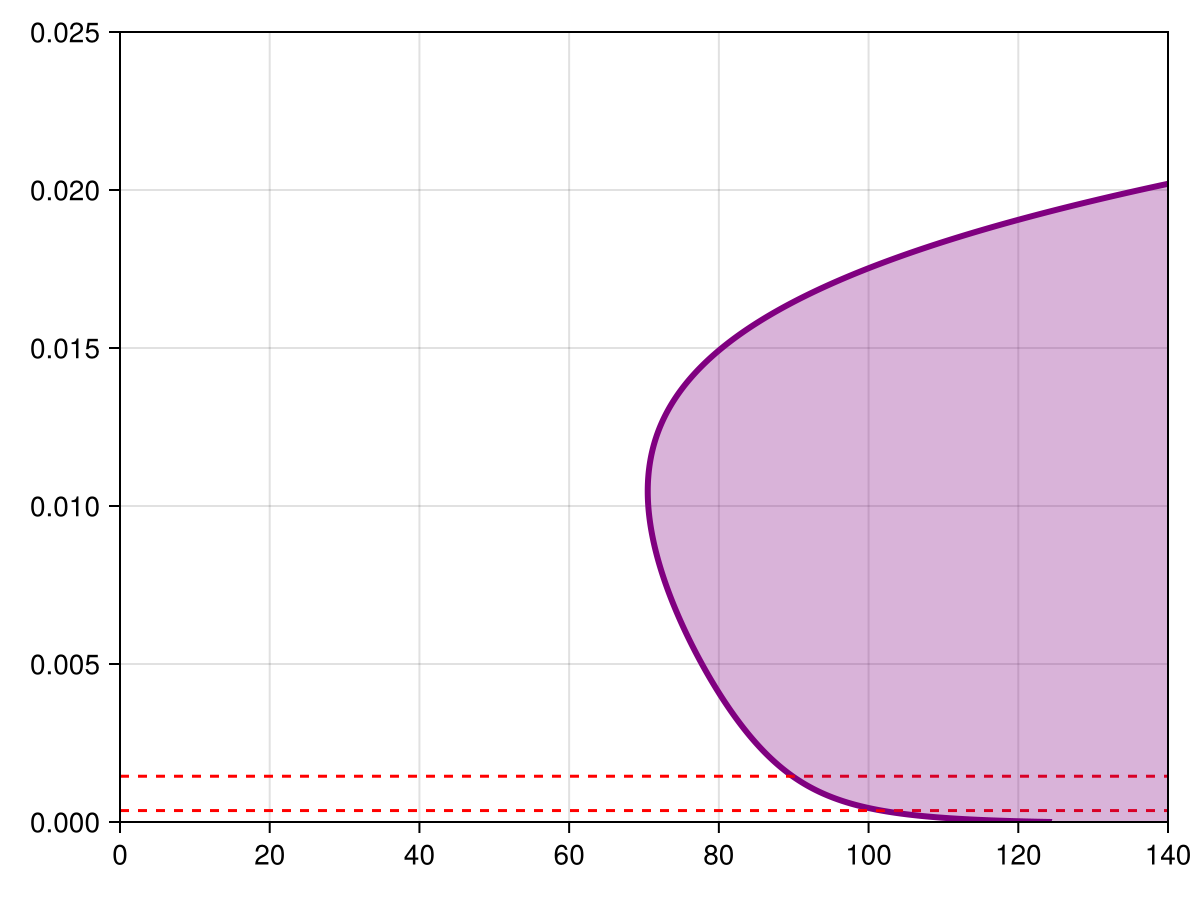

CairoMakie.Screen{IMAGE}


In [98]:
default(fontfamily="Arial",framestyle=:box, label=nothing, grid=true,tickfont = font(15, "Arial"),tick_direction=:out,thickness_scaling = 1.)
fig=Figure()
ax = Axis(
    fig[1, 1],
    limits = ((0,140),(0,0.025)))

lines!(ax,br_NaCl.param,br_NaCl.x,linewidth=3, color=:purple)
hlines!(ax,[0.02/55.25,0.08/55.25],color="red",linestyle=:dash)
band!(ax, br_NaCl.x, br_NaCl.param,140*ones(size(br_NaCl.param)), direction = :y, color = (:purple, 0.3))

#plot!([0,200],[0.08/55.25,0.08/55.35],color="red",style=:dash)
display(fig)

In [87]:
save("diagram_monovalent_chi_"*string(p.χ)*".svg",fig)

CairoMakie.Screen{SVG}


In [105]:
fun=br_NaCl.param.-121
idxs=findall(fun[1:end-1].*fun[2:end].<=0) # vector of starting point for the two branches
print(br_NaCl.x[idxs])

[1.739428739496836e-5, 0.019119244631116486]

In [111]:
p=@set p.χ=0.855
p=@set p.λ=121.

br_MgCl=Dict()
for nb in 1:length(idxs)
    X0=br_NaCl.sol[idxs[nb]].x
    p=@set p.zcat=1.
    opt_newton = NewtonPar(tol = 1e-9, verbose = true, max_iterations = 50)
    prob = BifurcationProblem(coexistence_system, X0, p, (@optic _.zcat);record_from_solution =(x, p; k...) ->exp(x[4])/(1+exp(x[4])))
    sol = BK.solve(prob, Newton(), opt_newton)
    u0 = sol.u
    prob = re_make(prob, u0=u0)

    opts_br = ContinuationPar(dsmin=1e-5, dsmax=0.1, ds=0.001,save_sol_every_step=1,
                          p_min = 1., p_max = 2.05,
                          max_steps = 25000,
                          newton_options = NewtonPar(tol=1e-9, max_iterations=2), detect_bifurcation=0)
    brzp= BK.continuation(prob, PALC(), opts_br,bothside=true);
    
    zcat=2.
    idxz=argmin((brzp.param .-zcat).^2)
    p=@set p.zcat=zcat
    u0=brzp.sol[idxz].x

    prob = BifurcationProblem(coexistence_system, u0, p, (@optic _.λ);record_from_solution =(x, u; k...) ->total_salt(10^p.exphiP1,x,p))
    sol = BK.solve(prob, Newton(), opt_newton)
    u0 = sol.u;
    prob = re_make(prob, u0=u0)

    opts_br = ContinuationPar(dsmin=1e-4, dsmax=0.1, ds=0.001,save_sol_every_step=1,
                              p_min = 0.01, p_max = 800.,
                              max_steps = 2000,
                              newton_options = NewtonPar(tol=1e-9, max_iterations=2), detect_bifurcation=1)
    br_MgCl["branch"*string(nb)]= BK.continuation(prob, PALC(), opts_br,bothside=true);
    nb+=1
end


┌─────────────────────────────────────────────────────┐
│ Newton step         residual      linear iterations │
├─────────────┬──────────────────────┬────────────────┤
│       0     │       1.7178e-03     │        0       │
│       1     │       9.3059e-06     │        1       │
│       2     │       1.6271e-10     │        1       │
└─────────────┴──────────────────────┴────────────────┘

┌─────────────────────────────────────────────────────┐
│ Newton step         residual      linear iterations │
├─────────────┬──────────────────────┬────────────────┤
│       0     │       1.5794e-02     │        0       │
│       1     │       4.5766e-05     │        1       │
│       2     │       3.1425e-10     │        1       │
└─────────────┴──────────────────────┴────────────────┘

┌─────────────────────────────────────────────────────┐
│ Newton step         residual      linear iterations │
├─────────────┬──────────────────────┬────────────────┤
│       0     │       4.8649e-05     │       

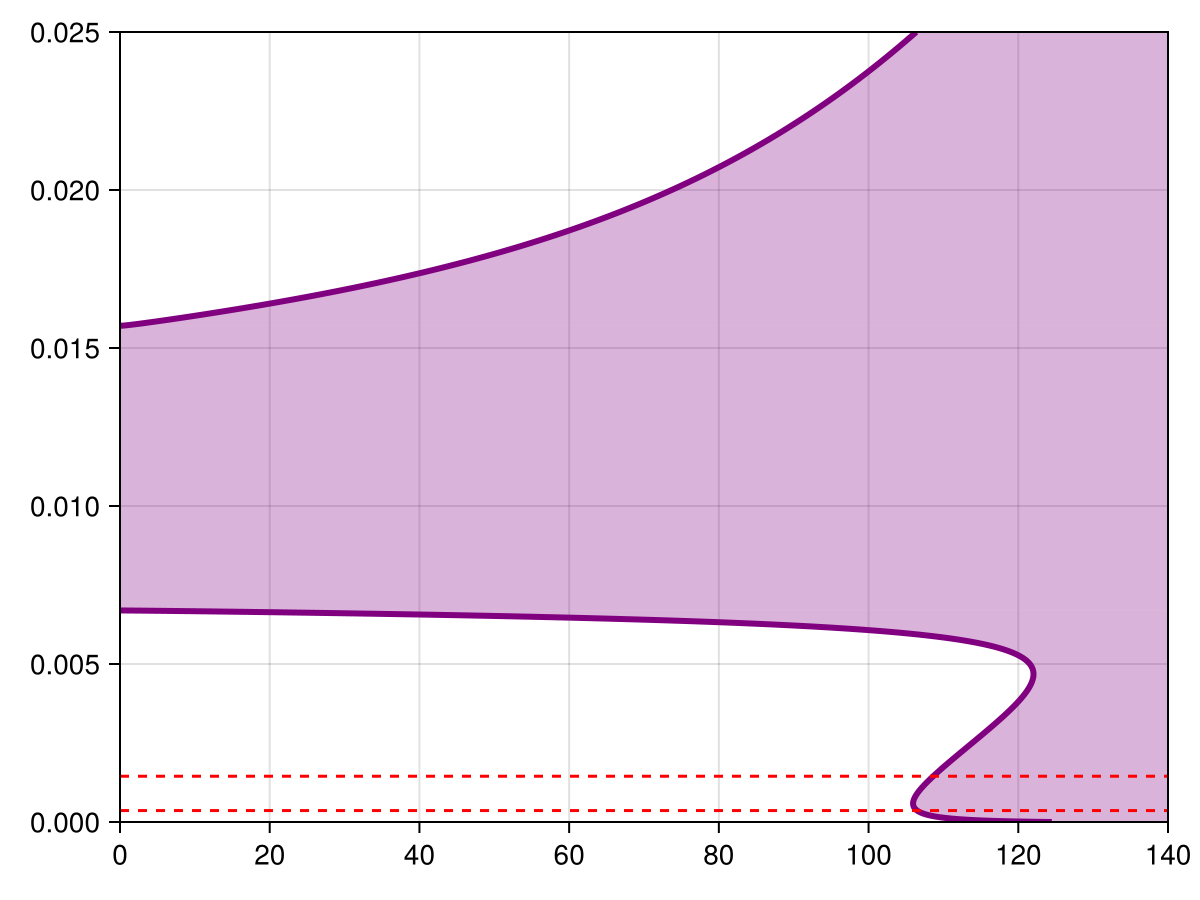

In [114]:
fig=Figure()
ax = Axis(
    fig[1, 1],
    limits = ((0,140),(0,0.025)))

for nel in keys(br_MgCl)
    lines!(ax,br_MgCl[nel],linewidth=3,color=:purple)
    band!(ax, br_MgCl[nel].x,br_MgCl[nel].param,140*ones(size(br_MgCl[nel].param)), direction = :y, color = (:purple, 0.3))
end
ϕs1=maximum(br_MgCl["branch1"].x)
ϕs2=minimum(br_MgCl["branch2"].x)

band!(ax,[ϕs1,ϕs2],[0,0],[140,140], direction = :y, color = (:purple, 0.3))
hlines!(ax,[0.02/55.25,0.08/55.25],color="red",linestyle=:dash)


fig